# Across-subject testing 

This test is designed to compare two datasets across individuals. A common use case is to relate brain dynamics to behavioral measurements, but the method is flexible and can be applied to other types of data too.

In this example, we use a Gaussian HMM trained on synthetic resting-state-like fMRI data. Our goal is to see whether differences in brain state dynamics across individuals are linked to a behavioral variable.

- The brain data (D) contains summary statistics from the HMM such as fractional occupancy (FO).

- The behavioral data (R) includes one simulated variable

We use permutation testing to assess whether there is a significant relationship between D and R.

In [18]:
import numpy as np
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from glhmm import glhmm, preproc, io, graphics, statistics
np.random.seed(0)  # For reproducibility

``data_raw``: simulated resting-state-like fMRI time series
Shape (n_timepoints × n_subjects, n_parcellations) : 480,000 × 50 — where 480,000 = 4800 timepoints × 100 subjects
Each row is a timepoint; each column corresponds to one of 50 parcellations

``data_behav``: simulated behavioral value
Shape (n_subjects,): 1D array with one value for each of 100 subjects

``data_confounds``: one confounding variable per subject
Shape (n_subjects,): 1D array with one value for each of 100 subjects

``idx_time``: session boundaries
Shape (n_subjects, 2): 2D array with 10 rows — each row defines the start and end index for a subjects

In [19]:
# Load data from csv files and convert to numpy arrays
data_raw = pd.read_csv('./Prediction/tc_forpred.csv', header=None).to_numpy()
idx_time = pd.read_csv('./Prediction/T_forpred.csv', header=None).to_numpy()
data_behav = np.squeeze(pd.read_csv('./Prediction/Y_forpred.csv', header=None).to_numpy())
data_confounds = np.squeeze(pd.read_csv('./Prediction/confounds_forpred.csv', header=None).to_numpy())

# Check that dimensions are correct
print("data_raw:", data_raw.shape)         # should be (n_subjects*n_timepoints, n_parcels)
print("data_behav:", data_behav.shape)     # should be (n_subjects,) or (n_subjects, 1)
print("idx_time:", idx_time.shape)         # should be (n_subjects, 2)
print("data_confounds:", data_confounds.shape) # should be (n_subjects,) or (n_subjects, n_confounds)

data_raw: (480000, 50)
data_behav: (100,)
idx_time: (100, 2)
data_confounds: (100,)


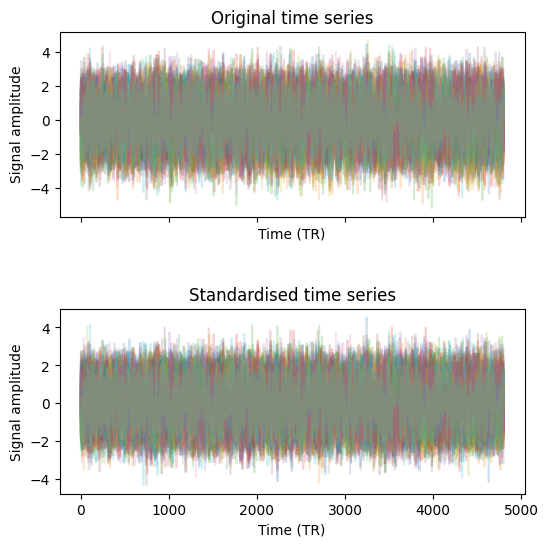

In [20]:
data_preproc, _, _= preproc.preprocess_data(data_raw, idx_time)

# Plot time series before and after standardisation for one subject
fig, (ax0, ax1) = plt.subplots(nrows=2, sharex=True, figsize=(6, 6))

ax0.plot(data_raw[0:4800, :], alpha=0.2)
ax0.set_xlabel("Time (TR)")
ax0.set_ylabel("Signal amplitude")
ax0.set_title("Original time series")

ax1.plot(data_preproc[0:4800, :], alpha=0.2)
ax1.set_xlabel("Time (TR)")
ax1.set_ylabel("Signal amplitude")
ax1.set_title("Standardised time series")

plt.subplots_adjust(hspace=0.5)
plt.show()

# Load pre-trained Gaussian HMM on fMRI data

In [21]:
hmm = io.load_hmm('./Prediction/hmm_pred.pkl')

In [22]:
# Decode Gamma (state probabilities)
Gamma, _, _ = hmm.decode(X=None, Y=data_preproc, indices=idx_time)

**HMM-aggregated statistics**

Fractional occupancy (FO) measures the proportion of time each subject spends in each state.

In [23]:
FO = glhmm.utils.get_FO(Gamma, idx_time)

print("FO shape:", FO.shape)
print("Behavioral data shape:", data_behav.shape)

FO shape: (100, 6)
Behavioral data shape: (100,)


**Visualise fractional occupancy**

This plot shows the FO for each subject across the six states.

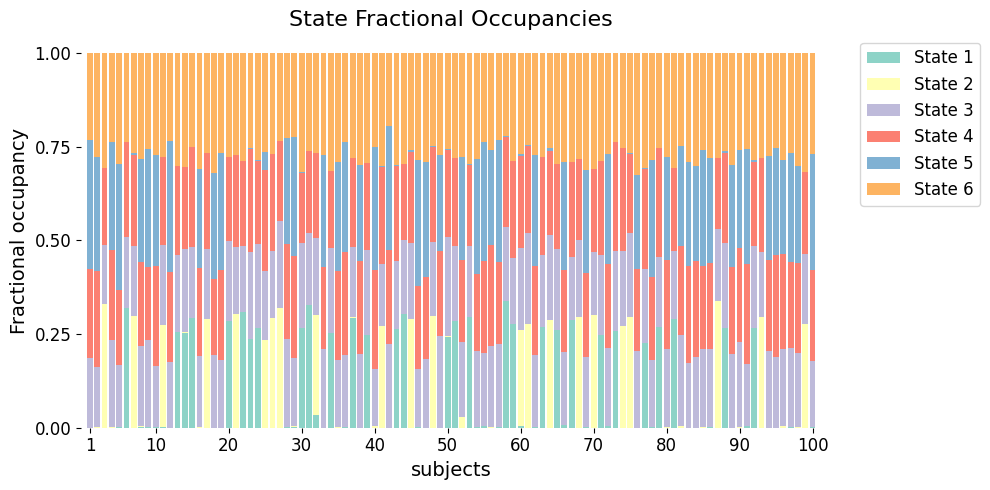

In [24]:
graphics.plot_FO(FO, xlabel="subjects", figsize=(10, 5))

# Across subjects – Multivariate

The multivariate test looks at all FO values together to see if they jointly explain variation in the behavioral variable.



In [25]:
# Setting up the parameters for the across-subjects test
method = "multivariate" # Method for testing (default = "multivariate")
Nnull_samples = 10_000 # Number of permutations (default = 0)

# Perform across-subject testing
result_multivariate  =statistics.test_across_subjects(D_data=FO,
                                                      R_data=data_behav,
                                                      method=method,
                                                      Nnull_samples=Nnull_samples,
                                                      )

Total possible permutations: 2.84e+35659
Running number of permutations: 10000


100%|██████████| 10000/10000 [00:01<00:00, 5097.57it/s]


In [26]:
statistics.display_test_summary(result_multivariate)


Model Summary:
   Outcome  r2_score  F-stat  df1  df2  p-value
Response 1    0.5412 18.4798    6   94   0.0001

Coefficients Table:
  Predictor    Outcome    T-stat  p-value      LLCI     ULCI
Predictor 1 Response 1  8.296513   0.0000 -1.961452 1.985079
Predictor 2 Response 1 -6.374727   0.0000 -1.900505 1.995623
Predictor 3 Response 1 -0.079045   0.9386 -1.910925 2.037905
Predictor 4 Response 1  0.770700   0.4431 -2.029676 1.990662
Predictor 5 Response 1 -1.301730   0.1995 -1.980317 1.950440
Predictor 6 Response 1  0.557638   0.5752 -1.952185 1.987820


**Visualisation of results**

After running the multivariate test, we can visualise the results using a simple bar plot of p-values. We will use the function plot_p_values_bar from the graphics module > Lower p-values (below α = 0.05) are shown in warm colours, while higher p-values are shown in cool colours.

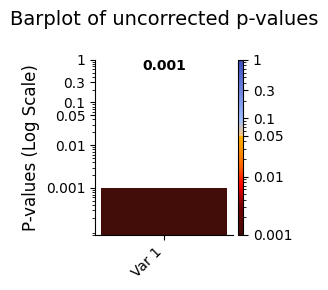

In [27]:
# Plot p-values
graphics.plot_p_values_bar(result_multivariate["pval"],
                           title_text ="Barplot of uncorrected p-values",
                      figsize=(3, 3), alpha=0.05)

# Across subjects – Univariate

This version tests each state individually. It assesses whether variation in a single state’s FO across subjects explains the behavioral variable.

Each test is run separately and produces one p-value per state. This allows for identifying specific states that show a strong effect.

In [28]:
# Set the parameters for between-subject testing
method = "univariate"
Nnull_samples = 10_000 # Number of permutations (default = 0)
# Perform across-subject testing
result_univariate  =statistics.test_across_subjects(D_data=FO,
                                                    R_data=data_behav,
                                                    method=method,
                                                    Nnull_samples=Nnull_samples,)

Total possible permutations: 2.84e+35659
Running number of permutations: 10000


100%|██████████| 10000/10000 [00:00<00:00, 12380.60it/s]


In [29]:
statistics.display_test_summary(result_univariate)


Model Summary:
              Unit  Nnull_samples
t_stat_independent          10000

Coefficients Table:
  Predictor    Outcome  Base Statistic  P-value
Predictor 1 Response 1        8.296513   0.0001
Predictor 2 Response 1       -6.374727   0.0001
Predictor 3 Response 1       -0.079045   0.9401
Predictor 4 Response 1        0.770700   0.4454
Predictor 5 Response 1       -1.301730   0.2009
Predictor 6 Response 1        0.557638   0.5781


**Visualisation of results**

To get a quick view of the results across all states: Again, we use plot_p_values_bar to display the uncorrected p-values.


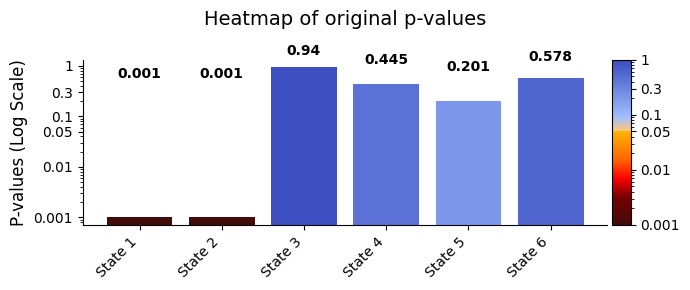

In [30]:
# Plot p-values
graphics.plot_p_values_bar(result_univariate["pval"].T,
                           title_text ="Heatmap of original p-values",
                            figsize=(7, 3),
                            xticklabels="State"
                            )

**Multiple testing correction**

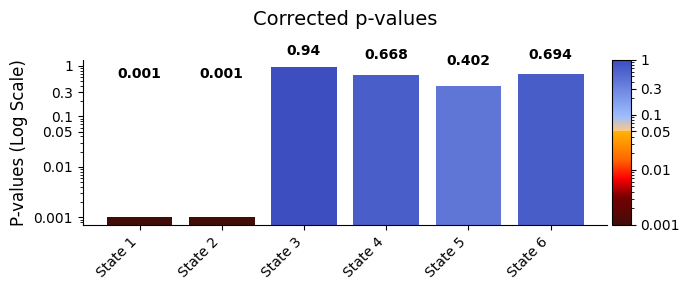

In [31]:
pval_corrected, rejected_corrected = statistics.pval_correction(
    result_univariate,
    method="fdr_bh"
)

# Plot p-values
graphics.plot_p_values_bar(pval_corrected,
                           title_text ="Corrected p-values",
                            figsize=(7, 3), xticklabels="State"
                            )

# Plot permutation distributions

These plots show the distribution of test statistics under the null for each state. The red line marks the observed value.

C:\Users\pipo_\AppData\Roaming\Python\Python310\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\pipo_\AppData\Roaming\Python\Python310\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


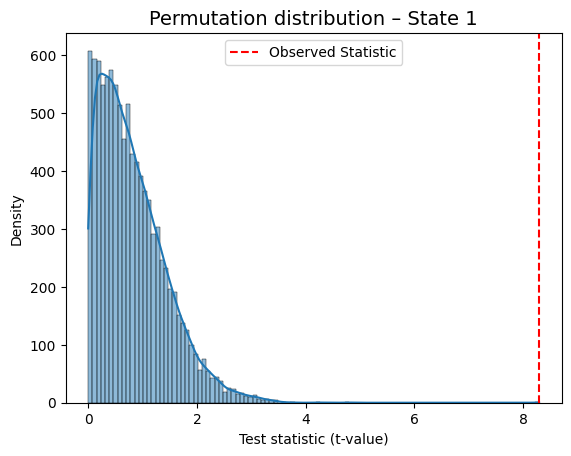

C:\Users\pipo_\AppData\Roaming\Python\Python310\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\pipo_\AppData\Roaming\Python\Python310\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


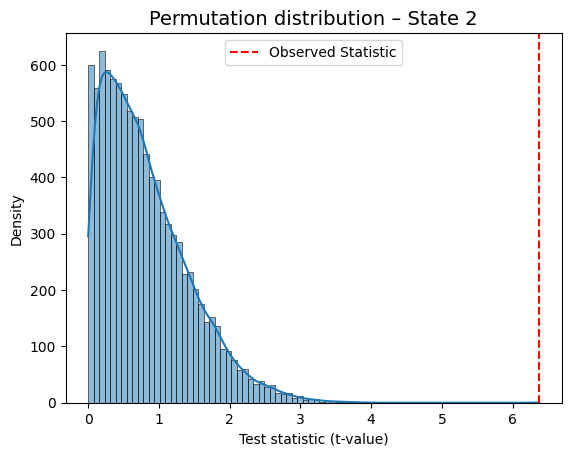

C:\Users\pipo_\AppData\Roaming\Python\Python310\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\pipo_\AppData\Roaming\Python\Python310\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


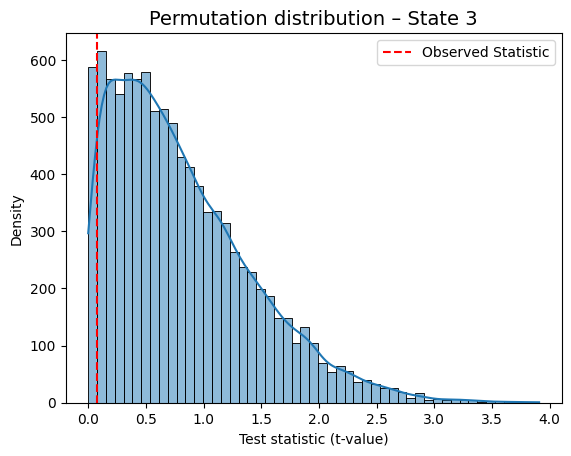

C:\Users\pipo_\AppData\Roaming\Python\Python310\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\pipo_\AppData\Roaming\Python\Python310\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


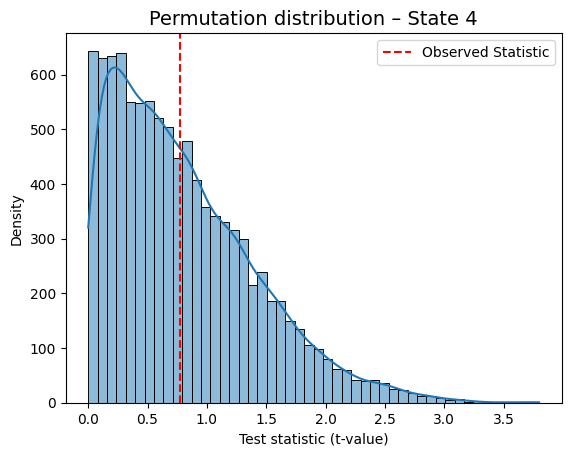

C:\Users\pipo_\AppData\Roaming\Python\Python310\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\pipo_\AppData\Roaming\Python\Python310\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


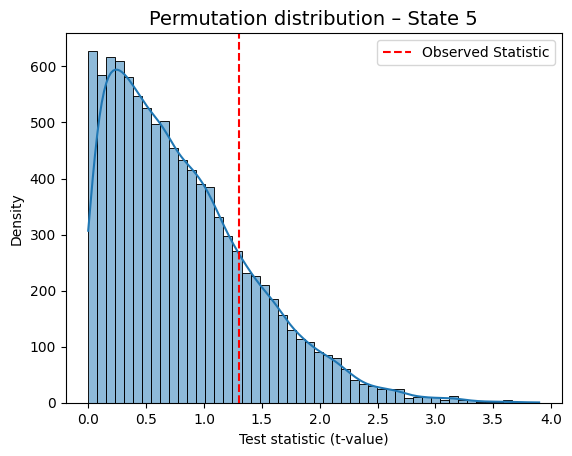

C:\Users\pipo_\AppData\Roaming\Python\Python310\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\pipo_\AppData\Roaming\Python\Python310\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


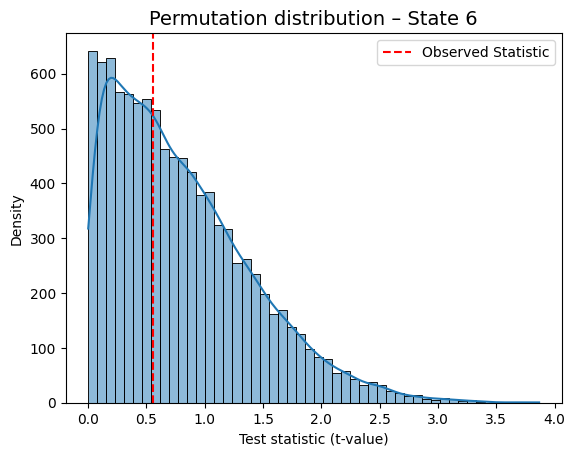

In [32]:
xlabel = "Test statistic (t-value)"

for i in range(result_univariate["null_stat_distribution"].shape[1]):
    graphics.plot_permutation_distribution(
        result_univariate["null_stat_distribution"][:, i],
        title_text=f"Permutation distribution – State {i+1}",
        xlabel=xlabel
    )